## Problem 2: Doppler effect
*50-60 points*

In this problem, we provide a sound sample exhibiting the Doppler effect. To make life difficult, the audio sample is not just a single frequency, but rather contains a few frequencies plus some noise, emulating a train horn. We will determine the velocity of the train. 

Assuming the train is traveling directly towards/away from the microphone, the formula for the Doppler equation is:

$$
f(t) = \frac{f_0}{1\pm \frac{v}{c}}.
$$

where $f_0$ is the emitted frequency, $v$ is the train speed, and $c=343.4\text{m/s}$ is the speed of sound. The frequency of the approaching train, $f_a=f_0/(1-v/c)$, is higher, and the frequency of the receding train, $f_r=f_0/(1+v/c)$, is lower.

Do your work in `midterm/problem2/problem2.ipynb`. The notebook demonstrates how to load the audio file into a numpy array. *You are allowed to use any FFT algorithm*, including `np.fft`, which is considerably faster than our in-class python function. Make sure to read the numpy documentation and understand the function.


### Problem 2a: data visualization
*10 points*

Our tool for frequency analysis will be the Fourier transform. To get a feel for the data, **take the FFT and plot the power spectrum versus frequency**. Use a logarithmic y-axis. As usual, you should pad the data to the nearest power of 2 and apply a window function. You should also convert the spectral index to frequency. Comment on all the features you can see in the power spectrum.

Note: you may want to write a generic function for this task, as you will be performing a few more FFTs in this problem. 


### Problem 2b: frequency analysis aka spectrogram
*20 points*

The big difference from methods covered in lecture is that we want to analyze a changing frequency versus time. So, we have to break up the data into smaller intervals, each corresponding to a frequency measurement at a fixed time. This is called a *short time Fourier transform*. Specifically, we set a frame length, $\Delta t$, for the chunks. The $\Delta t$ should be long enough for a good Fourier transform (i.e. contain enough cycles at the desired frequencies), but short enough that the frequency barely changes within one frame (and to avoid unnecessary computational time). 

**Write a function** to perform the STFT. The function should accept an argument for the desired time, $t$, as well as the frame length, $\Delta t$. In other words, the STFT will perform an FFT on the data in the time window $[t-\Delta t/2,\ t+\Delta t/2]$. 

**Use the function** to perform STFTs at a single representative $t$ for the following window sizes: 0.02s, 0.1s, and 0.5s. Comment on any differences, and choose a single $\Delta t$ value to use for the rest of the problem. 

Finally, **evaluate and plot the STFT** for the full sample. You should evaluate it at $t$ values with slightly smaller spacing than $\Delta t$, so that the frames overlap slightly between consecutive points (this gives a smooth result). The plot should have time on the x-axis, frequency on the y-axis, and the Fourier power on the z-axis (color scale), using `plt.pcolormesh` with a logarithmic z-axis. You should see the three peaks and the shift due to the Doppler effect.


### Problem 2c: velocity extraction
*20 points*

For each of the 3 tones, **estimate the asymptotic frequency values**: the "approaching frequency", $f_a$, and the "receding frequency", $f_r$. Specifically, determine the average frequency for the first and last 2s of the sample. For **PHY410 students**: identifying the 3 maxima of the FFT power spectra is sufficient, using e.g. `np.argmax` in the vicinity of the peaks. For **PHY505 students**: to identify the frequency more precisely, please either (a) do parabolic interpolation of the peak, i.e., fit the log of the nearest 3 points with a parabola and find the maximum; or (b) aggressively zero-pad to $2^{17}=131,072$ to obtain a finer frequency grid in your FFT. 

Based on the extracted frequencies:

1. What is the velocity of the train? Report the mean and the spread of the values obtained from the 3 tones.
2. What is $f_0$, the emitted frequency? Reminder: this is the harmonic mean of $f_a$ and $f_r$.


### Problem 2d: non-radial motion
*10 points*

**PHY505 students only**

The Doppler formula used so far assumes the train is heading directly at the microphone. However, the sample was actually generated assuming that the microphone is placed a distance $d$ away from the train tracks (which is, in general, a good life practice). Accounting for $d>0$, the Doppler formula is:

$$
f(t) = \frac{f_0}{1 + \frac{v}{c}\frac{x}{\sqrt{x^2+d^2}}}, \qquad x(t) \approx v(t - t_c)
$$

where $f_0$ is the emitted frequency, $v$ is the train speed, $c=343.4\text{m/s}$ is the speed of sound, $d$ is the distance of closest approach, $x$ is the train's position along the track, and $t_c$ is the time of closest approach (Note: more precisely, we should account for the sound travel time. For example, the time of closest approach, $t_0$, is not exactly the same as the time of measuring the sound emitted at $t_0$: $t_c=t_0+d/c$. For this problem, however, this is a tiny correction.). 

We can correct for non-radial motion with a linear fit. For $|x| \gg d$, the Doppler formula is approximately:

$$
f(t) \approx f_{\pm\infty} + \frac{K_{\pm}}{(t-t_c)^2}
$$

Thus, we can use linear least-squares fitting to extract $f_{\pm\infty}$ (we don't care about $K_{\pm}$). Specifically:

1. Estimate $t_c$, the time at which $f(t)=(f_a+f_r)/2$. 
2. For the first and last 2s of the data, perform linear fit of $f(t)$ vs. $1/(t-t_c)^2$, and record the constant term, $f_{\pm \infty}$.
3. Using $f_{\pm \infty}$, what is $v$? How does it compare to the answer from (2c)?


## Starter code: loading the audio file

`doppler.wav` is a 16-bit mono WAV file. `scipy.io.wavfile.read` returns the sample rate and an integer array; we convert it to floats in [-1, 1).

sample rate 44100 Hz, 705600 samples, duration 16.00 s


/var/folders/x4/dc9xrhvj3hl5swzhx2hd6hjh0000gq/T/ipykernel_34978/362844621.py:7: WavFileWarning: Chunk (non-data) not understood, skipping it.
  fs, x = wavfile.read("doppler.wav")     # fs = sample rate (Hz), x = int16 samples


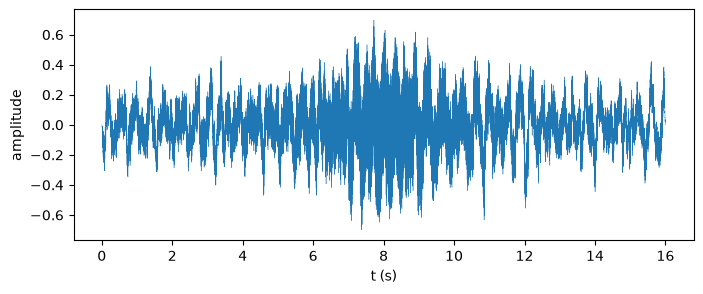

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

c = 343.4   # speed of sound (m/s)

fs, x = wavfile.read("doppler.wav")     # fs = sample rate (Hz), x = int16 samples
x = x.astype(float) / 32768             # normalize to [-1, 1)
t = np.arange(x.size) / fs              # time of each sample (s)
print(f"sample rate {fs} Hz, {x.size} samples, duration {x.size/fs:.2f} s")

plt.figure(figsize=(8, 3))
plt.plot(t, x, lw=0.3)
plt.xlabel("t (s)")
plt.ylabel("amplitude")
plt.show()

In [2]:
from IPython.display import Audio, display
Audio("doppler.wav")

In [ ]:
# Problem 2a: power spectrum of the full sample
# Step 1: subtract offset, apply a window, zero-pad to the next power of 2
# Step 2: FFT (e.g. np.fft.rfft) -> power spectrum
# Step 3: convert index to frequency (e.g. np.fft.rfftfreq); plot with a log y-axis
# Step 4: comment on the features you see


In [ ]:
# Problem 2b: short time Fourier transform
def stft(x, fs, t, dt):
    """Return (frequencies, power) of the windowed FFT of x in the time window [t - dt/2, t + dt/2]."""
    raise NotImplementedError

# Step 1: compare dt = 0.02, 0.1, 0.5 s at one representative t; choose dt
# Step 2: evaluate stft() on a grid of times (spacing slightly smaller than dt)
# Step 3: plt.pcolormesh(times, freqs, power.T, norm="log"); you may want to zoom the y-axis to < 1 kHz


In [ ]:
# Problem 2c: velocity
# Step 1: for each tone, find the peak frequency in each frame (np.argmax in a band around the tone)
#         PHY505: parabolic interpolation, or zero-pad each frame to 2**17
# Step 2: f_a and f_r = mean frequency in the first and last 2 s
# Step 3: v for each tone; mean and spread
# Step 4: emitted frequency f0 (harmonic mean of f_a and f_r)


In [ ]:
# Problem 2d: PHY505 students only (PHY410 extra credit)
# Step 1: estimate t_c, where f(t) = (f_a + f_r)/2
# Step 2: for the first and last 2 s, linear fit of f vs. 1/(t - t_c)^2; the constant term is f_(+-infinity)
# Step 3: v from f_(+-infinity); compare with 2c
